mplement K-Means clustering/ hierarchical clustering on sales_data_sample.csv dataset.
Determine the number of clusters using the elbow method.
Dataset link : https://www.kaggle.com/datasets/kyanyoga/sample-sales-data

To implement the K-Means Clustering algorithm on the sales dataset and determine the optimal number of clusters using the Elbow Method.

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


In [ ]:
df=pd.read_csv('sales_data_sample.csv',encoding="latin1") #character encoding that helps Python read files containing special characters without causing encoding errors. when not stored in utf-8
df.head()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [16]:
df.shape

(2823, 25)

In [17]:
# preprocesing
df.isnull().sum() 


ORDERNUMBER            0
QUANTITYORDERED        0
PRICEEACH              0
ORDERLINENUMBER        0
SALES                  0
ORDERDATE              0
STATUS                 0
QTR_ID                 0
MONTH_ID               0
YEAR_ID                0
PRODUCTLINE            0
MSRP                   0
PRODUCTCODE            0
CUSTOMERNAME           0
PHONE                  0
ADDRESSLINE1           0
ADDRESSLINE2        2521
CITY                   0
STATE               1486
POSTALCODE            76
COUNTRY                0
TERRITORY           1074
CONTACTLASTNAME        0
CONTACTFIRSTNAME       0
DEALSIZE               0
dtype: int64

In [18]:
df.duplicated().sum()

np.int64(0)

In [19]:
cols = df[['QUANTITYORDERED', 'PRICEEACH', 'SALES', 'MSRP']].copy()

# K-Means needs numerical features to calculate distances.You selected onl
# y four numerical columns.

# The other columns are not passed to the model.

# Therefore, their missing values do not affect your current clustering.

In [20]:
# feature scaling

scaler=StandardScaler()
cols_scaled=scaler.fit_transform(cols)

In [21]:
print(type(cols_scaled))
print(cols_scaled.shape)

<class 'numpy.ndarray'>
(2823, 4)


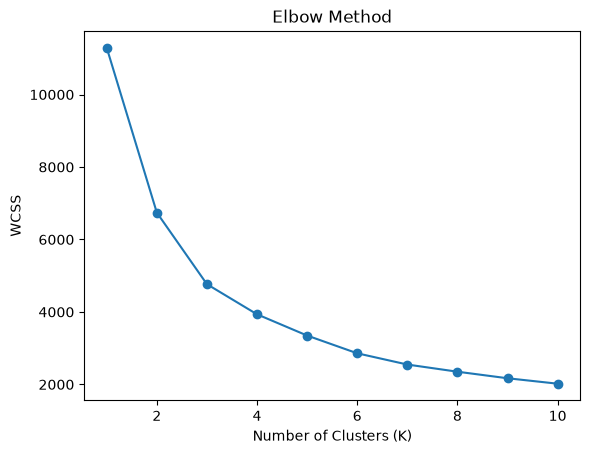

In [ ]:
wcss = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10) #
    model.fit(cols_scaled)
    wcss.append(model.inertia_) #inertia_ gives the WCSS value.

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

In [23]:
#the best choice is 3 clusters.
# Why?
# - K = 1 to 3: WCSS decreases sharply.
# - After K = 3: The decrease becomes slower.
# - The curve starts bending around K = 3.

kmeans=KMeans(n_clusters=3,random_state=42,n_init=10)
y_pred=kmeans.fit_predict(cols_scaled)

In [ ]:
print("WCSS:", kmeans.inertia_)
print("Silhouette Score:", silhouette_score(cols_scaled, y_pred))

# Measures how well the clusters are formed and separated.

# Its value ranges from -1 to +1.

# Closer to +1 means better-separated clusters.

WCSS: 4766.014280081645
Silhouette Score: 0.35088588055088427


In [ ]:
cols['Cluster'] = y_pred
print("\nCluster Count:")
print(cols['Cluster'].value_counts()) #the number of records in each cluster.(Counts data points in each cluster.)



Cluster Count:
Cluster
2    996
0    975
1    852
Name: count, dtype: int64


In [31]:
print("\nCluster Data:")
print(cols.head())


Cluster Data:
   QUANTITYORDERED  PRICEEACH    SALES  MSRP  Cluster
0               30      95.70  2871.00    95        2
1               34      81.35  2765.90    95        2
2               41      94.74  3884.34    95        1
3               45      83.26  3746.70    95        1
4               49     100.00  5205.27    95        1


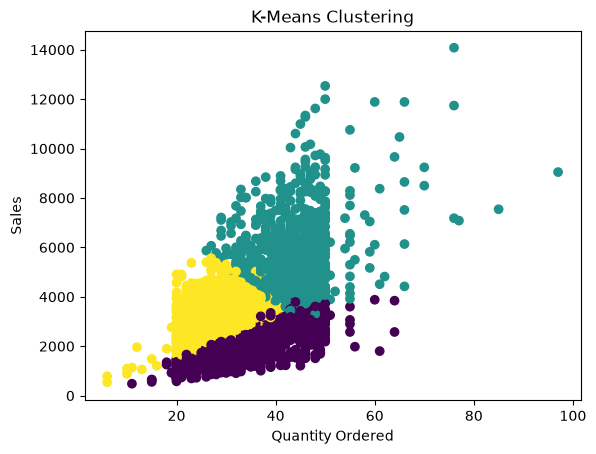

In [ ]:
plt.scatter(cols['QUANTITYORDERED'], cols['SALES'], c=y_pred, cmap='viridis')
plt.xlabel("Quantity Ordered")
plt.ylabel("Sales")
plt.title("K-Means Clustering")
plt.show()

# QUANTITYORDERED → X-axis.
# SALES → Y-axis.
# c=y_pred → Assigns colors based on cluster numbers.
# cmap='viridis' → Sets the color scheme.